## ResNet Evaluation (3)

Pick samples for Toloka experiment based on model's confidence (prediction and explanation confidence).

In [1]:
import sys
sys.path.append('./wingbeats/')

In [2]:
import numpy as np
import glob, os
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.layers.experimental.preprocessing import Rescaling
from sklearn.preprocessing import OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-02-01 10:03:06.591860: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-02-01 10:03:07.136858: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
metafolder = './beexplainable/metafiles/Fungi/raw/'

FUNGI_PATH = '../data/DanishFungi/DF20M_3spec/'
IMAGES_PATH = metafolder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + 'classes.txt'
CONCEPTS_PATH = '../data/DanishFungi/Concepts_3spec/'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/'

## Load images

#### Original Raw Mushrooms

In [5]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true_bees = list( img_label_dict.values() )
y_true_bees = np.asarray(y_true_bees, dtype = np.uint8) - 1

# Read class names and concepts
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [6]:
batch_size = 64#len(file_ids)
img_height = img_width = 224

In [7]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH),
                                          label)

2024-02-01 10:03:07.208479: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [8]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true_bees, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

#### Concepts

In [9]:
# Store concepts, image paths and create label vector from subfolder names
concepts, concept_files, y_true_con = [], [], []
concept_subfolders = sorted( glob.glob(CONCEPTS_PATH + '*') )
for i in range(len(concept_subfolders)):
    # Add concept from subfolder base name
    concept = os.path.basename(concept_subfolders[i])
    concepts.append( concept )

    # Get image paths in current concept subfolder (there are .jpg and .png files)
    c_files = glob.glob(CONCEPTS_PATH + concept + '/*.jpg') + glob.glob(CONCEPTS_PATH + concept + '/*.png')
    concept_files += [c[len(CONCEPTS_PATH):] for c in c_files] # remove the constant path to the common dir.
    y_true_con += [i] * len(c_files)

concepts

['bright_red', 'reddish_orange', 'rose_red']

In [10]:
# Define file ids (for consistency with the parsers in the pipeline)
# Note: the metafile readers return a Dict[str, str]
file_ids_con = [str(i) for i in range(1, len(y_true_con)+1)]

In [11]:
# Get dictionary of file IDs and file names
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_con, concept_files),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, CONCEPTS_PATH),
                                          label)

In [12]:
# Conversion to tf.Dataset
concept_set = ps.parse_to_dataset(file_ids_con, y_true_con, parse_image_lab)
concept_set = concept_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
concept_set = concept_set.map(lambda x, y: (normalization_layer(x), y))

In [13]:
for image_batch, labels_batch in concept_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=int32)


Mapping relevant concepts to true class labels

In [14]:
# One-hot-encode the concepts
enc = OneHotEncoder().fit([[0], [1], [2]])
concept_basis = enc.transform([[0], [1], [2]]).toarray()

In [15]:
# R.emetica:  bright red
# R.paludosa: reddish orange
# R.rosea:    rose red
lookup_cls_concepts = [concept_basis[0],
                       concept_basis[1],
                       concept_basis[2]]
lookup_cls_concepts[0]

array([1., 0., 0.])

## Load Model

In [16]:
# Define model parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-3, 1e-3

constructor =  wm.build_simple_classifier
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'raw'
init = 'iNat' if load_pretrained_backbone else 'Imagenet'

out_shape = len(classes)
model_name = 'ResNet50_' + init + '_' + input_form + '_Fungi' # model was trained on raw whole dataset
weights_file = MODELS_PATH + 'all/Fungi/' + model_name + '/' + model_name + '.h5' # path to load weights from
print('Model loaded from ' + weights_file)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not (must be set to True even if just loading weights and doing inference)
trainable = True

Model loaded from ./beexplainable/models/all/Fungi/ResNet50_iNat_raw_Fungi/ResNet50_iNat_raw_Fungi.h5


In [17]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

### Store class prediction vectors

In [18]:
# Class probabilities on whole test set
#pred_vecs = model.predict(test_set, verbose=1)

In [19]:
# Store vectors as numpy array
#np.save(metafolder + 'softmax_preds.npy', pred_vecs)
loaded_soft = np.load(metafolder + 'softmax_preds.npy')
loaded_soft[:10]

array([[9.9828255e-01, 3.4332933e-04, 1.3741218e-03],
       [9.8645210e-01, 1.2925715e-02, 6.2213652e-04],
       [7.2737521e-01, 4.3096356e-02, 2.2952840e-01],
       [9.9989259e-01, 4.8675897e-06, 1.0253805e-04],
       [9.9999785e-01, 8.1613069e-07, 1.2672115e-06],
       [9.9244869e-01, 4.7263275e-03, 2.8250436e-03],
       [9.9997973e-01, 1.8877463e-05, 1.4601103e-06],
       [9.6918046e-01, 2.4910882e-02, 5.9085861e-03],
       [9.9414188e-01, 7.7977451e-04, 5.0782575e-03],
       [9.9790883e-01, 1.5402640e-03, 5.5093801e-04]], dtype=float32)

### Store kNN predictions for the concepts

In [20]:
# Extract features of concept images with ResNet backbone
#res_concepts = []
#for img, lab in concept_set.unbatch():
#    res_concepts.append( cnn.resnet.predict(tf.expand_dims(img, axis=0)) )
#res_concepts = tf.squeeze(res_concepts, axis=1)
#tf.shape(res_concepts)

In [21]:
# Fit KNN on CNN activations
#neigh = KNeighborsClassifier(n_neighbors=10)
#neigh.fit(res_concepts, y_true_con)

In [22]:
# Extract features from ResNet backbone
#test_activations = cnn.resnet.predict(test_set, verbose=1)
#test_activations.shape

In [23]:
# Predict concept probabilities for the extracted features
#knn_probs = neigh.predict_proba(test_activations)

In [24]:
# Store vectors as numpy array
#np.save(metafolder + 'knn_probs.npy', knn_probs)
loaded_knn = np.load(metafolder + 'knn_probs.npy')
loaded_knn[:10]

array([[0.2, 0.5, 0.3],
       [0.3, 0.5, 0.2],
       [0.4, 0.3, 0.3],
       [0.4, 0.2, 0.4],
       [0.8, 0.2, 0. ],
       [0.5, 0.2, 0.3],
       [0.6, 0.2, 0.2],
       [0.4, 0.5, 0.1],
       [0.3, 0.4, 0.3],
       [0.6, 0.2, 0.2]])

Investigate samples for their model's uncertainty

In [25]:
#np.where(loaded_soft[51:270][:,1] < 0.75)

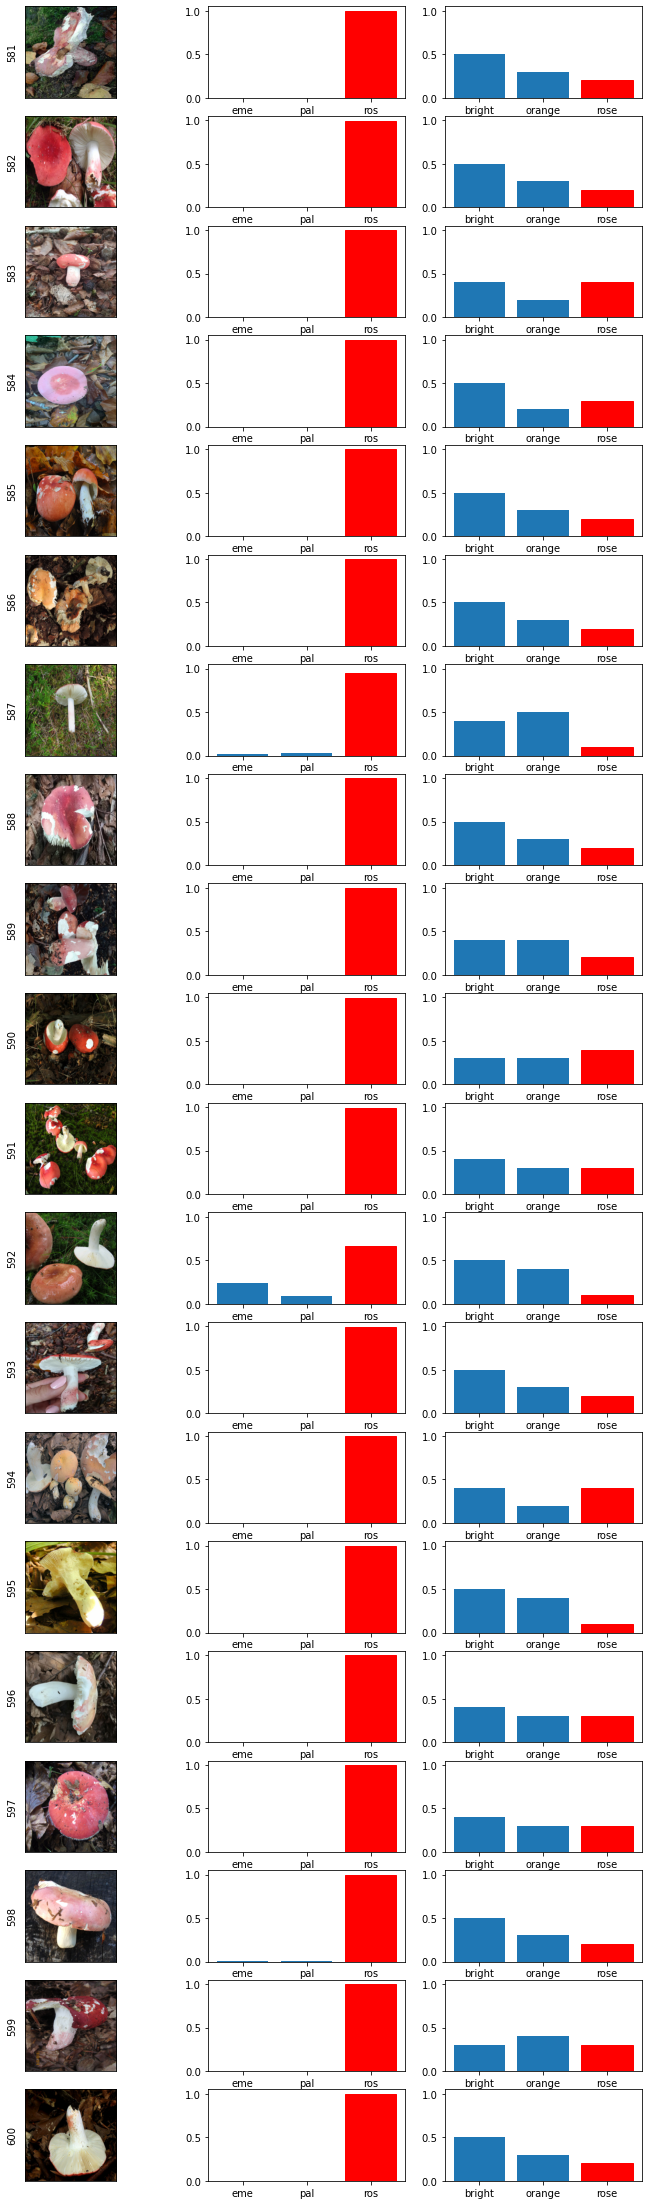

In [26]:
num_cols, num_rows, start_id = 3, 20, 580
plt.figure(figsize=(12, 2*num_rows))
for i in range(start_id, start_id+num_rows):
    sample = img_dict[str(i+1)] # i.e. Andrena_bicolor/Andrena_bicolor_2799379_1.jpg
    cls = classes[ y_true_bees[i] ]

    raw_file = '../data/DanishFungi/DF20M_3spec/' + sample
    im = np.asarray( Image.open(raw_file).resize((224, 224)) )
    plt.subplot(num_rows, num_cols, num_cols*(i-start_id)+1)
    plt.imshow(im); plt.xticks([]); plt.yticks([])
    plt.ylabel(i+1)
    if i == 0: plt.title('Test sample')

    plt.subplot(num_rows, num_cols, num_cols*(i-start_id)+2)
    barlist = plt.bar(np.arange(len(classes)), loaded_soft[i])
    barlist[y_true_bees[i]].set_color('r') # mark bar for the true species
    plt.xticks(np.arange(len(classes)), ['eme', 'pal', 'ros'])
    plt.ylim([0.0, 1.05])
    if i == 0: plt.title('Model class pred.')

    plt.subplot(num_rows, num_cols, num_cols*(i-start_id)+3)
    barlist = plt.bar(np.arange(3), loaded_knn[i])
    correct_con_ids = np.where( lookup_cls_concepts[y_true_bees[i]] == 1.0 )[0]
    for corr_id in correct_con_ids:
        barlist[corr_id].set_color('r') # mark bars for the true concepts
    plt.xticks(np.arange(3), ['bright', 'orange', 'rose'])
    plt.ylim([0.0, 1.05])
    if i == 0: plt.title('Model concept pred.')
plt.show()

### Plot Images along with Predicted Species (for Control Group in Toloka)

In [ ]:
task13_paths = glob.glob('./beexplainable/toloka/fungi/images/task13_imgs/*.JPG')
for img in task13_paths:
    img_id = img.split('/')[-1].split('_')[0] # i.e. the number in 2237915051-225385_rosea_hard_wrong.JPG
    for key in img_dict:
        if img_id in img_dict[key]:
            spec_pred_id = np.argmax(loaded_soft[int(key)-1], axis=-1)

            f = plt.figure(figsize=(7, 7))
            plt.title('Our model predicted ' + classes[spec_pred_id].replace('_', ' '), color='red', fontsize=20, weight='bold')

            raw_file = '../data/DanishFungi/DF20M_3spec/' + img_dict[key]
            im = np.asarray( Image.open(raw_file).resize((448, 448)) )
            plt.imshow(im); plt.xticks([]); plt.yticks([])

            plt.tight_layout()
            f.savefig('./beexplainable/toloka/fungi/images/task2_control_imgs/' + img.split('/')[-1])
            break

### Plot Images along with Predicted Species and Confidence (for Control_Conf Group in Toloka)

In [ ]:
task13_paths = glob.glob('./beexplainable/toloka/fungi/images/task13_imgs/*.JPG')
for img in task13_paths:
    img_id = img.split('/')[-1].split('_')[0] # i.e. the number in 2237915051-225385_rosea_hard_wrong.JPG
    for key in img_dict:
        if img_id in img_dict[key]:
            spec_pred_id = np.argmax(loaded_soft[int(key)-1], axis=-1)
            spec_pred_prob = int(np.round(np.max(loaded_soft[int(key)-1]),2)*100)

            f = plt.figure(figsize=(7, 7))
            plt.title('Our model is ' + str(spec_pred_prob) + '% confident\nthat this bee is ' +
                      classes[spec_pred_id].replace('_', ' '),
                      color='red', fontsize=20, weight='bold')

            raw_file = '../data/DanishFungi/DF20M_3spec/' + img_dict[key]
            im = np.asarray( Image.open(raw_file).resize((448, 448)) )
            plt.imshow(im); plt.xticks([]); plt.yticks([])

            plt.tight_layout()
            f.savefig('./beexplainable/toloka/fungi/images/task2_control_conf_imgs/' + img.split('/')[-1])
            break

### Plot Images along with Predicted Species, Confidence and Concepts (for XAI Group in Toloka)

In [26]:
task13_paths = glob.glob('./beexplainable/toloka/fungi/images/task13_imgs/*.JPG')
BASE_PATH_CONCEPTS = './beexplainable/toloka/fungi/images/concepts/'
concept_paths = [BASE_PATH_CONCEPTS + 'xai_concepts_emetica_text.PNG',
                 BASE_PATH_CONCEPTS + 'xai_concepts_paludosa_text.PNG',
                 BASE_PATH_CONCEPTS + 'xai_concepts_rosea_text.PNG']

In [ ]:
for img in task13_paths:
    img_id = img.split('/')[-1].split('_')[0] # i.e. the number in 2237915051-225385_rosea_hard_wrong.JPG
    for key in img_dict:
        if img_id in img_dict[key]:
            spec_pred_id = np.argmax(loaded_soft[int(key)-1], axis=-1)
            spec_true = 'Russula_' + img.split('/')[-1].split('_')[1]
            spec_true_id = classes.index(spec_true)

            # Whenever there is a tie in the top 2 predicted concepts, show the concept corresponding to the predicted class
            # If it's not part of the top 2, show concept corresponding to the true class
            # If it's that's also not in top 2, show the first concept in the top 2
            # Note: For only 3 concepts, you will always fall into one of the first two cases.
            con_pred_top2 = np.argsort(loaded_knn[int(key)-1])[-2:]
            if spec_pred_id in con_pred_top2:
                con_pred = spec_pred_id
            elif spec_true_id in con_pred_top2:
                con_pred = spec_true_id
            else:
                con_pred = con_pred_top2[0]

            f, (a0, a1) = plt.subplots(2, 1, figsize=(10, 10), gridspec_kw={'height_ratios': [5, 3]})
            raw_file = '../data/DanishFungi/DF20M_3spec/' + img_dict[key]
            im = np.asarray( Image.open(raw_file).resize((448, 448)) )
            a0.imshow(im)
            a0.axes.get_xaxis().set_ticks([])
            a0.axes.get_yaxis().set_ticks([])

            con = np.asarray( Image.open(concept_paths[con_pred]).resize((620, 224)) )
            a1.imshow(con)
            a1.set_title('Our model is ' + str(spec_pred_prob) + '% confident\nthat this bee is ' +
                         classes[spec_pred_id].replace('_', ' ') + ' because:',
                         color='red', fontsize=25, weight='bold')
            a1.axes.get_xaxis().set_ticks([])
            a1.axes.get_yaxis().set_ticks([])

            f.tight_layout()
            f.savefig('./beexplainable/toloka/fungi/images/task2_concepts_knn_imgs/' + img.split('/')[-1])
            break